# College Football Upset Vulnerability — Notebook 12: Returning Production and Roster Continuity


## 0. Load project artifacts and freeze the experimental rules



In [ ]:
%pip -q install pyarrow requests

from pathlib import Path
import json, re, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, requests
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, log_loss, roc_auc_score
from google.colab import drive

drive.mount('/content/drive')
PROJECT_DIR = Path('/content/drive/MyDrive/CFB_Upset_Project')
PROCESSED = PROJECT_DIR / 'data' / 'processed'
REFERENCE = PROJECT_DIR / 'data' / 'reference'
OUTPUT_DIR = PROJECT_DIR / 'outputs' / 'validation'
RP_CACHE = REFERENCE / 'returning_production'
RP_CACHE.mkdir(parents=True, exist_ok=True)

INPUTS = {
    'n09_matchups': PROCESSED / 'matchup_features_offense_defense.csv',
    'n09_manifest': PROCESSED / 'offense_defense_feature_manifest.json',
    'n10_matchups': PROCESSED / 'matchup_features_historical_efficiency_elo.csv',
    'n11_elo': PROCESSED / 'elo_parameter_variants_pregame_2004_2023.csv',
    'n11_oof': OUTPUT_DIR / 'elo_parameter_model_oof_predictions_2019_2023.csv',
    'eligibility': PROCESSED / 'game_eligibility_and_splits.csv',
    'splits': PROCESSED / 'split_manifest.json',
    'team_seasons': PROCESSED / 'team_season_subdivisions.csv',
    'membership_reference': REFERENCE / 'cfb_team_group_seasons.parquet',
}
missing = [f'{name}: {p}' for name, p in INPUTS.items() if not p.is_file()]
if missing:
    raise FileNotFoundError('Run exports from Notebooks 03, 09, 10, 11 first. Missing:\n' + '\n'.join(missing))
matchups = pd.read_csv(INPUTS['n09_matchups'], parse_dates=['date'], low_memory=False)
n10 = pd.read_csv(INPUTS['n10_matchups'], low_memory=False)
elo = pd.read_csv(INPUTS['n11_elo'], low_memory=False)
prior_oof = pd.read_csv(INPUTS['n11_oof'], low_memory=False)
eligibility = pd.read_csv(INPUTS['eligibility'], low_memory=False)
team_seasons = pd.read_csv(INPUTS['team_seasons'], low_memory=False)
manifest09 = json.loads(INPUTS['n09_manifest'].read_text(encoding='utf-8'))
splits = json.loads(INPUTS['splits'].read_text(encoding='utf-8'))
BASE88 = list(manifest09['feature_sets']['efficiency_without_scoring'])
FOLDS = splits['validation_folds']
TEST_SEASONS = set(map(int, splits['test_seasons']))
assert TEST_SEASONS == {2024,2025}
assert [int(f['validation_season']) for f in FOLDS] == [2019,2020,2021,2022,2023]
assert len(BASE88)==88 and len(set(BASE88))==88 and set(BASE88).issubset(matchups.columns)
assert matchups.game_id.is_unique and n10.game_id.is_unique and elo.game_id.is_unique
assert len(matchups)==18300 and len(n10)==18300
print('Loaded base matchups:',len(matchups),'| base features:',len(BASE88))
print('Validation folds:',[f['validation_season'] for f in FOLDS])
print('Holdout reserved:',sorted(TEST_SEASONS))
print('Software versions: pandas',pd.__version__,'scikit-learn',sklearn.__version__)

Mounted at /content/drive
Loaded base matchups: 18300 | base features: 88
Validation folds: [2019, 2020, 2021, 2022, 2023]
Holdout reserved: [2024, 2025]
Software versions: pandas 2.2.3 scikit-learn 1.6.1


## 1. Download and cache published returning-production seasons (2004–2023 only)


In [ ]:
from datetime import datetime, timezone
RP_BASE = ('https://github.com/sportsdataverse/sportsdataverse-data/'
           'releases/download/cfb_returning_production/')
MODEL_YEARS = list(range(2004,2019)) + [2019,2020,2021,2022,2023]
SCHEMA = ['season','team_id','off_returning','def_returning','overall_returning',
          'n_returning','def_basis','overall_basis','is_estimated']

def download_if_missing(year):
    target = RP_CACHE / f'cfb_returning_production_{year}.parquet'
    if not target.exists():
        url = RP_BASE + target.name
        response = requests.get(url,timeout=120,headers={'User-Agent':'CFB-Upset-Academic-Research/1.0'})
        response.raise_for_status()
        raw = response.content
        if not raw.startswith(b'PAR1') or not raw.endswith(b'PAR1'):
            raise ValueError(f'Expected Parquet for {year}; received {len(raw)} bytes.')
        target.write_bytes(raw)
    return target

frames=[];source_rows=[]
for year in MODEL_YEARS:
    p = download_if_missing(year)
    frame = pd.read_parquet(p)
    if not set(SCHEMA).issubset(frame.columns):
        raise ValueError(f'Unexpected returning-production schema for {year}: {frame.columns.tolist()}')
    assert frame['season'].notna().all() and frame['season'].astype(int).eq(year).all(),year
    assert frame['team_id'].notna().all()
    assert not frame.duplicated(['season','team_id']).any(),year
    frames.append(frame[SCHEMA].copy())
    source_rows.append({'season':year,'rows':len(frame),'source_file':p.name,
                        'source_size_bytes':p.stat().st_size,'url':RP_BASE+p.name})
rp_raw=pd.concat(frames,ignore_index=True)
rp_sources=pd.DataFrame(source_rows)
assert not rp_raw.duplicated(['season','team_id']).any()
assert rp_raw.season.between(2004,2023).all()
print('Returning-production team-season rows:',len(rp_raw),'| seasons:',rp_raw.season.nunique())
print('Source files in Drive:',RP_CACHE)
display(rp_sources.tail(8))
print('Defensive measurement definitions:')
display(pd.crosstab(rp_raw.season,rp_raw.def_basis,dropna=False).tail(12))

Returning-production team-season rows: 3925 | seasons: 20
Source files in Drive: /content/drive/MyDrive/CFB_Upset_Project/data/reference/returning_production


,season,rows,source_file,source_size_bytes,url
12,2016,214,cfb_returning_production_2016.parquet,8773,https://github.com/sportsdataverse/sportsdatav...
13,2017,222,cfb_returning_production_2017.parquet,9021,https://github.com/sportsdataverse/sportsdatav...
14,2018,218,cfb_returning_production_2018.parquet,8902,https://github.com/sportsdataverse/sportsdatav...
15,2019,225,cfb_returning_production_2019.parquet,8885,https://github.com/sportsdataverse/sportsdatav...
16,2020,223,cfb_returning_production_2020.parquet,7363,https://github.com/sportsdataverse/sportsdatav...
17,2021,146,cfb_returning_production_2021.parquet,7217,https://github.com/sportsdataverse/sportsdatav...
18,2022,233,cfb_returning_production_2022.parquet,9328,https://github.com/sportsdataverse/sportsdatav...
19,2023,234,cfb_returning_production_2023.parquet,9342,https://github.com/sportsdataverse/sportsdatav...


Defensive measurement definitions:


def_basis,participants,pbp_splash,NaN
season,,,
2012,0,165,32
2013,0,168,34
2014,0,175,35
2015,210,0,4
2016,213,0,1
2017,219,0,3
2018,217,0,1
2019,224,0,1
2020,220,0,3


## 2. Join ESPN team IDs through the same season-specific membership mapping used in Notebook 03



In [ ]:
membership = pd.read_parquet(INPUTS['membership_reference'])
needed = {'season','team_name','team_id','team_id_source'}
assert needed.issubset(membership.columns),membership.columns.tolist()
membership = membership.loc[membership.season.between(2004,2023),list(needed)].copy()
assert not membership.duplicated(['season','team_name']).any(), 'Ambiguous membership team names'
assert {'season','team','team_name','subdivision'}.issubset(team_seasons.columns)

def id_string(col):
    return col.astype('string').str.strip().str.replace(r'\.0$','',regex=True)

membership['team_id']=id_string(membership['team_id'])
team_key = team_seasons.loc[team_seasons.season.between(2004,2023),
                            ['season','team','team_name','subdivision']].copy()
assert not team_key.duplicated(['season','team']).any()
team_key = team_key.merge(membership,on=['season','team_name'],how='left',
                          validate='many_to_one',indicator=True)
team_key['valid_espn_id'] = team_key['team_id'].notna() & team_key['team_id_source'].eq('espn')
team_key['espn_team_id'] = team_key['team_id'].where(team_key.valid_espn_id)
assert not team_key.loc[team_key.espn_team_id.notna()].duplicated(['season','espn_team_id']).any(), 'Multiple named teams share one ESPN ID'

rp_raw['team_id']=id_string(rp_raw.team_id)
for field in ['off_returning','def_returning','overall_returning','n_returning']:
    rp_raw[field]=pd.to_numeric(rp_raw[field],errors='coerce')
# Save truly missing values as NaN. Unexpected out-of-range shares get flagged
# and excluded from modeling rather than clamped or assigned zero.
range_flags={}
for field in ['off_returning','def_returning','overall_returning']:
    bad = rp_raw[field].notna() & ~rp_raw[field].between(0,1)
    range_flags[field]=int(bad.sum())
    rp_raw.loc[bad,field]=np.nan
rp_raw['def_basis']=rp_raw['def_basis'].astype('string')
rp_raw['def_comparable']=rp_raw['def_basis'].eq('participants')
rp_raw['rp_def_conservative']=rp_raw['def_returning'].where(rp_raw.def_comparable)
# Keep source's overall aggregate for audit only; do not model it. Its weights
# were fitted on 2018–2025 data (not an independent pre-2019 feature design).
rp_small=rp_raw[['season','team_id','off_returning','rp_def_conservative',
                 'overall_returning','n_returning','def_basis','overall_basis','is_estimated']]
team_rp=team_key.merge(rp_small,left_on=['season','espn_team_id'],
                       right_on=['season','team_id'],how='left',validate='many_to_one',
                       suffixes=('','_rp'),indicator='rp_match')
team_rp['rp_found']=team_rp.rp_match.eq('both')
assert len(team_rp)==len(team_key) and not team_rp.duplicated(['season','team']).any()
print('Unexpected out-of-range shares excluded:',range_flags)
print('FBS team-seasons matched by year (RP record, usable offense, comparable defense):')
fbs=team_rp.loc[team_rp.subdivision.eq('fbs')]
coverage=fbs.groupby('season').agg(team_seasons=('team','size'),
    rp_record_found=('rp_found','sum'),offense_present=('off_returning','count'),
    defense_comparable_present=('rp_def_conservative','count'))
for col in ['rp_record_found','offense_present','defense_comparable_present']:
    coverage[col+'_pct']=coverage[col]/coverage.team_seasons

display(coverage.tail(12).round(3))
print('Unmatched verified FBS team-seasons in validation years:')
display(fbs.loc[fbs.season.between(2019,2023) & ~fbs.rp_found,
                ['season','team','team_name','espn_team_id','valid_espn_id']].head(35))
print('Reference namespace counts:')
display(team_key.team_id_source.value_counts(dropna=False))

Unexpected out-of-range shares excluded: {'off_returning': 0, 'def_returning': 0, 'overall_returning': 0}
FBS team-seasons matched by year (RP record, usable offense, comparable defense):


,team_seasons,rp_record_found,offense_present,defense_comparable_present,rp_record_found_pct,offense_present_pct,defense_comparable_present_pct
season,,,,,,,
2012,124,123,123,0,0.992,0.992,0.000
2013,125,124,124,0,0.992,0.992,0.000
2014,128,128,128,0,1.000,1.000,0.000
2015,128,127,127,127,0.992,0.992,0.992
2016,128,128,128,128,1.000,1.000,1.000
2017,130,128,128,128,0.985,0.985,0.985
2018,130,130,130,130,1.000,1.000,1.000
2019,130,130,130,130,1.000,1.000,1.000
2020,127,127,127,127,1.000,1.000,1.000


Unmatched verified FBS team-seasons in validation years:


,season,team,team_name,espn_team_id,valid_espn_id
711,2021,Connecticut,UConn,41,True
1416,2022,James Madison,James Madison,256,True
2451,2021,Old Dominion,Old Dominion,295,True


Reference namespace counts:


,count
team_id_source,
espn,3965
NaN,19


## 3. Build current-season retrospective versus previous-season lagged roster features



In [ ]:
COLUMNS=['off_returning','rp_def_conservative','n_returning']
team_features=team_key[['season','team','subdivision']].copy()
now=team_rp[['season','team',*COLUMNS]].rename(columns={
    'off_returning':'rp_current_off',
    'rp_def_conservative':'rp_current_def',
    'n_returning':'rp_current_n_players'})
prev=team_rp[['season','team',*COLUMNS]].copy()
prev['season']=prev.season+1
prev=prev.rename(columns={'off_returning':'rp_prev_off',
    'rp_def_conservative':'rp_prev_def','n_returning':'rp_prev_n_players'})
team_features=team_features.merge(now,on=['season','team'],how='left',validate='one_to_one')
team_features=team_features.merge(prev,on=['season','team'],how='left',validate='one_to_one')
for f in ['rp_current_off','rp_current_def','rp_prev_off','rp_prev_def']:
    vals=team_features[f].dropna()
    assert vals.between(0,1).all(),f

# Illustrate exactly what each figure means for a real team-season.
selected=['Kansas State','Georgia','Cincinnati','TCU','USC','Texas','Michigan']
print('Selected 2023 schools (current-year values are RETROSPECTIVE, not certified pregame):')
display(team_features.loc[team_features.season.eq(2023) & team_features.team.isin(selected),
    ['team','rp_current_off','rp_current_def','rp_prev_off','rp_prev_def']].sort_values('team').round(3))

# Verify shift: 2023 lagged values must equal the same school's 2022 source values.
check=team_features.loc[team_features.season.between(2005,2023),
    ['season','team','rp_prev_off','rp_prev_def']].copy()
manual=now[['season','team','rp_current_off','rp_current_def']].copy()
manual['season']+=1
verify=check.merge(manual,on=['season','team'],how='left',validate='one_to_one')
for old,new in [('rp_prev_off','rp_current_off'),('rp_prev_def','rp_current_def')]:
    assert np.allclose(verify[old].to_numpy(dtype=float),verify[new].to_numpy(dtype=float),
                       equal_nan=True,atol=0,rtol=0), (old,new)
assert not team_features.season.isin(TEST_SEASONS).any()
print('PASS: Lagged features equal the prior season source values exactly.')
print('PASS: 2024–2025 returning-production files were not loaded.')

Selected 2023 schools (current-year values are RETROSPECTIVE, not certified pregame):


,team,rp_current_off,rp_current_def,rp_prev_off,rp_prev_def
590,Cincinnati,0.191,0.407,0.292,0.369
1066,Georgia,0.432,0.615,0.674,0.446
1457,Kansas State,0.396,0.501,0.561,0.546
1785,Michigan,0.805,0.578,0.812,0.248
3077,TCU,0.130,0.540,0.854,0.625
3185,Texas,0.578,0.575,0.589,0.701
3508,USC,0.775,0.620,0.253,0.396


PASS: Lagged features equal the prior season source values exactly.
PASS: 2024–2025 returning-production files were not loaded.


## 4. Attach features to home/away teams; inspect missingness by validation year and season stage



In [ ]:
JOIN=['game_id','season','home','away']
all_games=matchups.loc[matchups.season.between(2004,2023)].copy()
COLS=['rp_current_off','rp_current_def','rp_prev_off','rp_prev_def']
for side in ['home','away']:
    sub=team_features[['season','team',*COLS]].rename(columns={'team':side,
        **{f:f'{side}_{f}' for f in COLS}})
    all_games=all_games.merge(sub,on=['season',side],how='left',validate='many_to_one',indicator=True)
    assert all_games['_merge'].eq('both').all(), 'Team-season key unmatched'
    all_games.drop(columns='_merge',inplace=True)
for f in COLS:
    all_games[f'diff_{f}']=all_games[f'home_{f}']-all_games[f'away_{f}']

# All reference snapshots are from earlier games or fixed team-season roster data.
# Attach winner-adjusted pregame Elo features from Notebook 11 and the invariant
# prior-game counts from Notebook 10 (the exact 6 features used in Notebook 11).
WINNER='mov_winner_adjusted'
elo_cols=[f'{WINNER}__elo_home_rating',f'{WINNER}__elo_away_rating',
          f'{WINNER}__elo_expected_home']
assert set(elo_cols).issubset(elo.columns)
assert {'elo_home_prior_games','elo_away_prior_games'}.issubset(n10.columns)
elo_sub=elo[['game_id',*elo_cols]].rename(columns={
    elo_cols[0]:'rp_elo_home_rating',elo_cols[1]:'rp_elo_away_rating',
    elo_cols[2]:'rp_elo_expected_home'})
all_games=all_games.merge(elo_sub,on='game_id',how='left',validate='one_to_one',indicator=True)
assert all_games['_merge'].eq('both').all()
all_games.drop(columns='_merge',inplace=True)
all_games=all_games.merge(n10[['game_id','elo_home_prior_games','elo_away_prior_games']],
                          on='game_id',how='left',validate='one_to_one')
all_games['rp_elo_diff']=all_games.rp_elo_home_rating-all_games.rp_elo_away_rating
ELO6=['rp_elo_home_rating','rp_elo_away_rating','rp_elo_diff','rp_elo_expected_home',
      'elo_home_prior_games','elo_away_prior_games']

# Stage and primary FBS-FBS population use the existing Notebook 03 definitions.
assert all_games.game_id.is_unique
all_games=all_games.merge(eligibility[JOIN+['primary_fbs_fbs']],
    on=JOIN,how='left',validate='one_to_one',indicator=True)
assert all_games['_merge'].eq('both').all()
all_games.drop(columns='_merge',inplace=True)
primary=all_games.loc[all_games.primary_fbs_fbs.astype('string').str.lower().isin(['true','1'])].copy()
assert len(primary)==14563 and primary.season.between(2004,2023).all()
assert primary.game_id.is_unique and len(primary.loc[primary.season.between(2019,2023)])==3646

coverage_by_year=[]
for season,g in primary.loc[primary.season.between(2019,2023)].groupby('season'):
    coverage_by_year.append({'season':int(season),'games':len(g),
        'both_off_current':float(g[['home_rp_current_off','away_rp_current_off']].notna().all(axis=1).mean()),
        'both_def_current':float(g[['home_rp_current_def','away_rp_current_def']].notna().all(axis=1).mean()),
        'both_off_prev':float(g[['home_rp_prev_off','away_rp_prev_off']].notna().all(axis=1).mean()),
        'both_def_prev':float(g[['home_rp_prev_def','away_rp_prev_def']].notna().all(axis=1).mean())})
match_coverage=pd.DataFrame(coverage_by_year)
print('Validation-game feature coverage (fraction with BOTH teams available):')
display(match_coverage.round(3))
print('Average coverage by pregame season stage:')
stage_cov=primary.loc[primary.season.between(2019,2023)].groupby('season_stage',observed=False).apply(
    lambda g:pd.Series({f:g[f].notna().mean() for f in
    ['home_rp_current_off','home_rp_current_def','home_rp_prev_off','home_rp_prev_def']}),
    include_groups=False)
display(stage_cov.round(3))

Validation-game feature coverage (fraction with BOTH teams available):


,season,games,both_off_current,both_def_current,both_off_prev,both_def_prev
0,2019,774,1.000,1.000,1.000,1.000
1,2020,534,1.000,1.000,1.000,1.000
2,2021,770,0.971,0.971,0.957,0.957
3,2022,776,0.987,0.987,0.957,0.957
4,2023,792,1.000,1.000,0.971,0.971


Average coverage by pregame season stage:


,home_rp_current_off,home_rp_current_def,home_rp_prev_off,home_rp_prev_def
season_stage,,,,
0 FBS games,0.998,0.998,0.990,0.990
1–3 FBS games,0.996,0.996,0.990,0.990
4–7 FBS games,0.997,0.997,0.988,0.988
8+ FBS games,0.995,0.995,0.989,0.989


## 5. Formal data-quality and provenance audit — inspect before interpreting results



In [ ]:
# No game is duplicated; no holdout rows are in the modeling population.
assert primary.game_id.is_unique
assert not primary.season.isin(TEST_SEASONS).any()
assert primary.home_win.isin([0,1]).all()
assert all(primary[col].notna().all() for col in ELO6)
assert all(not primary[col].isna().all() for col in
           ['home_rp_current_off','away_rp_current_off','home_rp_prev_off','away_rp_prev_off']),            'No roster data joined; check team-ID mapping and source files.'
# Double-check team-season constancy for every incoming roster field.
for side in ['home','away']:
    for col in COLS:
        vals=all_games.groupby(['season',side])[f'{side}_{col}'].nunique(dropna=False)
        assert vals.le(1).all(),(side,col,'roster values varied during a season')
for col in [f'{side}_{f}' for side in ['home','away'] for f in COLS]:
    assert primary[col].dropna().between(0,1).all(),col
assert set(BASE88).isdisjoint(COLS)

# Source's overall aggregate may contain information from its 2018–2025
# fitted weights; do not use it as an input in any MODEL_SETS below.
print('AUDIT SUMMARY')
print('Matched FBS team-seasons, 2019–2023:',
      fbs.loc[fbs.season.between(2019,2023),'rp_found'].sum(), 'of',
      len(fbs.loc[fbs.season.between(2019,2023)]))
print('Out-of-range shares excluded:',range_flags)
print('Defensive basis (source rows):')
display(rp_raw.groupby(['season','def_basis'],dropna=False).size().unstack(fill_value=0).tail(10))
print('Current-year roster values are RETROSPECTIVE; not certified point-in-time.')
print('Previous-year roster values are a one-year-lagged continuity proxy.')
print('PASS: No 2024–2025 game outcomes entered joins or model population.')
print('PASS: Roster features constant within each team-season and within valid share ranges.')

AUDIT SUMMARY
Matched FBS team-seasons, 2019–2023: 648 of 651
Out-of-range shares excluded: {'off_returning': 0, 'def_returning': 0, 'overall_returning': 0}
Defensive basis (source rows):


def_basis,participants,pbp_splash,<NA>
season,,,
2014,0,175,35
2015,210,0,4
2016,213,0,1
2017,219,0,3
2018,217,0,1
2019,224,0,1
2020,220,0,3
2021,145,0,1
2022,214,0,19


Current-year roster values are RETROSPECTIVE; not certified point-in-time.
Previous-year roster values are a one-year-lagged continuity proxy.
PASS: No 2024–2025 game outcomes entered joins or model population.
PASS: Roster features constant within each team-season and within valid share ranges.


## 6. Predeclare controlled exploratory model comparisons



In [ ]:
def side_and_diff(name):
    return [f'home_{name}',f'away_{name}',f'diff_{name}']
P_OFF=side_and_diff('rp_prev_off')
P_DEF=side_and_diff('rp_prev_def')
C_OFF=side_and_diff('rp_current_off')
C_DEF=side_and_diff('rp_current_def')
MODEL_SETS={
    'baseline_88': BASE88,
    'elo_winner_adjusted': BASE88+ELO6,
    'lagged_roster_off':BASE88+P_OFF,
    'lagged_roster_off_def':BASE88+P_OFF+P_DEF,
    'elo_plus_lagged_roster':BASE88+ELO6+P_OFF+P_DEF,
    'RETROSPECTIVE_current_off':BASE88+C_OFF,
    'RETROSPECTIVE_current_off_def':BASE88+C_OFF+C_DEF,
    'RETROSPECTIVE_elo_plus_current':BASE88+ELO6+C_OFF+C_DEF,
}
BANNED={'home_win','home_margin','score_home','score_away','date','game_id','season',
        'home','away','points_for','points_against','overall_returning','rp_current_n_players'}
for name,features in MODEL_SETS.items():
    assert len(features)==len(set(features)),name
    assert set(features).isdisjoint(BANNED),name
    assert set(features).issubset(primary.columns),name
    print(f'{name}: {len(features)} features')
for col in list(dict.fromkeys(c for f in MODEL_SETS.values() for c in f)):
    if col=='neutral':
        primary[col]=primary[col].astype('string').str.strip().str.lower().map(
            {'true':1.0,'false':0.0,'1':1.0,'0':0.0})
    else:
        original_na=int(primary[col].isna().sum())
        primary[col]=pd.to_numeric(primary[col],errors='coerce')
        assert int(primary[col].isna().sum())==original_na,('Unexpected conversion',col)
assert primary[BASE88].select_dtypes(exclude=[np.number]).empty
print('No restricted season/outcome column appears in model features.')

baseline_88: 88 features
elo_winner_adjusted: 94 features
lagged_roster_off: 91 features
lagged_roster_off_def: 94 features
elo_plus_lagged_roster: 100 features
RETROSPECTIVE_current_off: 91 features
RETROSPECTIVE_current_off_def: 94 features
RETROSPECTIVE_elo_plus_current: 100 features
No restricted season/outcome column appears in model features.


## 7. Five expanding-window folds: compare Brier, accuracy and AUC



In [ ]:
def make_pipeline():
    return Pipeline([
        ('imputer',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),
        ('scaler',StandardScaler()),
        ('classifier',LogisticRegression(solver='lbfgs',C=1.0,max_iter=2000,random_state=42)),
    ])

def evaluate(y,p):
    y=np.asarray(y).astype(int);p=np.asarray(p).astype(float)
    return {'n_games':int(len(y)),
            'accuracy':float(accuracy_score(y,p>=0.5)),
            'brier':float(brier_score_loss(y,p)),
            'log_loss':float(log_loss(y,np.clip(p,1e-12,1-1e-12),labels=[0,1])),
            'roc_auc':float(roc_auc_score(y,p))}

fold_rows=[];pred_parts=[]
for fold in FOLDS:
    year=int(fold['validation_season']);start,end=map(int,fold['train_seasons'])
    assert (start,end)==(2004,year-1)
    tr=primary.loc[primary.season.between(start,end)]
    va=primary.loc[primary.season.eq(year)]
    assert tr.season.max()<year and len(va)>0
    assert set(tr.game_id).isdisjoint(set(va.game_id))
    for label,features in MODEL_SETS.items():
        pipeline=make_pipeline()
        pipeline.fit(tr[features],tr.home_win.astype(int))
        p=pipeline.predict_proba(va[features])[:,list(pipeline.named_steps['classifier'].classes_).index(1)]
        fold_rows.append({'fold':fold['fold'],'validation_season':year,'model':label,
                          'n_train':int(len(tr)),**evaluate(va.home_win,p)})
        part=va[['game_id','season','date','home','away','home_win','season_stage']].copy()
        part['model']=label;part['p_home_win']=p
        pred_parts.append(part)
    print(f'{year}: {len(tr):,} training / {len(va):,} validation games')
fold_scores=pd.DataFrame(fold_rows)
oof=pd.concat(pred_parts,ignore_index=True)
assert oof.groupby('model').size().eq(3646).all()
assert not oof.season.isin(TEST_SEASONS).any()
assert oof.groupby(['model','game_id']).size().eq(1).all()

# Reproduce the adjusted-Elo benchmark from Notebook 11 within this notebook.
old=prior_oof.loc[prior_oof.model.eq('elo_mov_winner_adjusted'),
    ['game_id','home_win','predicted_p_home_win']].rename(
        columns={'predicted_p_home_win':'p11'})
new=oof.loc[oof.model.eq('elo_winner_adjusted'),
    ['game_id','home_win','p_home_win']].rename(columns={'p_home_win':'p12'})
repro=old.merge(new,on='game_id',how='outer',validate='one_to_one',indicator=True,
                suffixes=('_11','_12'))
assert len(repro)==3646 and repro['_merge'].eq('both').all()
assert (repro.home_win_11==repro.home_win_12).all()
diff=(repro.p11-repro.p12).abs()
reproduction={'mean_absolute_probability_difference':float(diff.mean()),
    'max_absolute_probability_difference':float(diff.max()),
    'changed_winner_predictions':int(((repro.p11>=.5)!=(repro.p12>=.5)).sum()),
    'abs_brier_difference':float(abs(brier_score_loss(repro.home_win_11,repro.p11)-
                        brier_score_loss(repro.home_win_12,repro.p12)))}
print('Notebook 11 adjusted-Elo reproduction:')
display(pd.Series(reproduction).to_frame('value'))
assert reproduction['abs_brier_difference']<1e-4, 'Substantial benchmark discrepancy; investigate.'

2019: 10,917 training / 774 validation games
2020: 11,691 training / 534 validation games
2021: 12,225 training / 770 validation games
2022: 12,995 training / 776 validation games
2023: 13,771 training / 792 validation games
Notebook 11 adjusted-Elo reproduction:


,value
mean_absolute_probability_difference,0.000667
max_absolute_probability_difference,0.016963
changed_winner_predictions,2.000000
abs_brier_difference,0.000031


## 8. Overall and per-stage results — label hindsight-dependent models


Pooled model comparison — DO NOT promote current-season roster variants yet:


,model,n_games,accuracy,brier,log_loss,roc_auc,provenance_status
0,RETROSPECTIVE_elo_plus_current,3646,0.715579,0.184034,0.545876,0.788249,retrospective current-season roster: timing un...
1,RETROSPECTIVE_current_off_def,3646,0.718047,0.185296,0.549937,0.784931,retrospective current-season roster: timing un...
2,RETROSPECTIVE_current_off,3646,0.719419,0.185809,0.551404,0.783657,retrospective current-season roster: timing un...
3,elo_winner_adjusted,3646,0.711465,0.186624,0.552768,0.781993,prior-year lagged or game-only
4,elo_plus_lagged_roster,3646,0.708996,0.186778,0.553324,0.781899,prior-year lagged or game-only
5,baseline_88,3646,0.719419,0.187238,0.555391,0.780032,prior-year lagged or game-only
6,lagged_roster_off,3646,0.715579,0.187360,0.555649,0.779945,prior-year lagged or game-only
7,lagged_roster_off_def,3646,0.713385,0.187658,0.556610,0.779272,prior-year lagged or game-only


Brier change by validation year relative to adjusted-Elo model (negative=better):


model,RETROSPECTIVE_current_off,RETROSPECTIVE_current_off_def,RETROSPECTIVE_elo_plus_current,baseline_88,elo_plus_lagged_roster,elo_winner_adjusted,lagged_roster_off,lagged_roster_off_def
season,,,,,,,,
2019,-0.00113,-0.00260,-0.00578,0.00159,0.00021,0.0,0.00225,0.00219
2020,-0.00383,-0.00488,-0.00264,-0.00244,-0.00009,0.0,-0.00267,-0.00194
2021,-0.00047,0.00033,0.00097,-0.00081,0.00013,0.0,-0.00054,-0.00067
2022,0.00046,-0.00073,-0.00339,0.00201,0.00067,0.0,0.00189,0.00294
2023,-0.00007,0.00012,-0.00211,0.00174,-0.00022,0.0,0.00166,0.00171


Brier by season stage:


model,RETROSPECTIVE_current_off,RETROSPECTIVE_current_off_def,RETROSPECTIVE_elo_plus_current,baseline_88,elo_plus_lagged_roster,elo_winner_adjusted,lagged_roster_off,lagged_roster_off_def
season_stage,,,,,,,,
0 FBS games,0.17589,0.17545,0.17156,0.17817,0.17678,0.17532,0.17873,0.18000
1–3 FBS games,0.18923,0.18868,0.18508,0.18983,0.18694,0.18673,0.18981,0.19033
4–7 FBS games,0.18493,0.18490,0.18716,0.18779,0.19115,0.19057,0.18819,0.18841
8+ FBS games,0.18742,0.18633,0.18414,0.18760,0.18527,0.18621,0.18734,0.18714


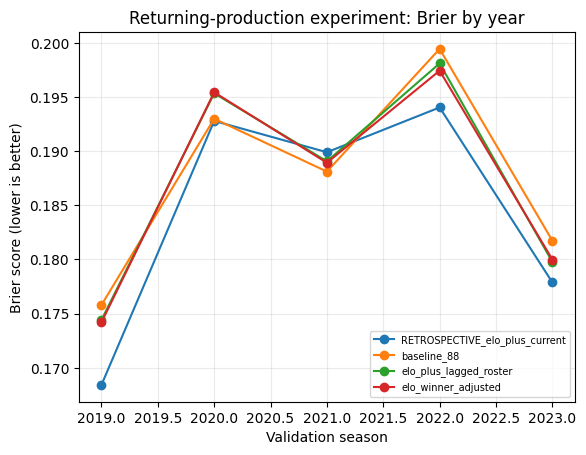

In [ ]:
pooled=pd.DataFrame([{'model':name,**evaluate(g.home_win,g.p_home_win)}
                     for name,g in oof.groupby('model')]).sort_values('brier').reset_index(drop=True)
pooled['provenance_status']=np.where(pooled.model.str.startswith('RETROSPECTIVE_'),
    'retrospective current-season roster: timing unverified',
    'prior-year lagged or game-only')
print('Pooled model comparison — DO NOT promote current-season roster variants yet:')
display(pooled.round(6))
by_year=pd.DataFrame([{'model':name,'season':int(season),**evaluate(g.home_win,g.p_home_win)}
             for (name,season),g in oof.groupby(['model','season'])])
by_stage=pd.DataFrame([{'model':name,'season_stage':stage,**evaluate(g.home_win,g.p_home_win)}
             for (name,stage),g in oof.groupby(['model','season_stage'],observed=False) if len(g)])
base=by_year.loc[by_year.model.eq('elo_winner_adjusted'),['season','brier']].rename(columns={'brier':'brier_elo_base'})
year_delta=by_year.merge(base,on='season',validate='many_to_one')
year_delta['brier_change_vs_elo']=year_delta.brier-year_delta.brier_elo_base
print('Brier change by validation year relative to adjusted-Elo model (negative=better):')
display(year_delta.pivot(index='season',columns='model',values='brier_change_vs_elo').round(5))
print('Brier by season stage:')
display(by_stage.pivot(index='season_stage',columns='model',values='brier').round(5))
plot_data=by_year.loc[by_year.model.isin([
    'baseline_88','elo_winner_adjusted','elo_plus_lagged_roster',
    'RETROSPECTIVE_elo_plus_current'])]
for name,g in plot_data.groupby('model'):
    plt.plot(g.season,g.brier,marker='o',label=name)
plt.xlabel('Validation season');plt.ylabel('Brier score (lower is better)')
plt.title('Returning-production experiment: Brier by year')
plt.legend(fontsize=7);plt.grid(alpha=.25);plt.show()

## 9. Export the audit and exploratory experiment artifacts



In [ ]:
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
PROCESSED.mkdir(parents=True,exist_ok=True)
EXPORTS={
    'returning_source_files':REFERENCE/'returning_production_source_manifest.csv',
    'returning_team_seasons':PROCESSED/'returning_production_team_seasons_2004_2023.csv',
    'returning_matchups':PROCESSED/'matchup_features_returning_production_2004_2023.csv',
    'returning_coverage_by_year':OUTPUT_DIR/'returning_production_coverage_by_year.csv',
    'returning_fold_scores':OUTPUT_DIR/'returning_production_fold_scores.csv',
    'returning_pooled_scores':OUTPUT_DIR/'returning_production_pooled_scores.csv',
    'returning_by_stage':OUTPUT_DIR/'returning_production_scores_by_stage.csv',
    'returning_oof_predictions':OUTPUT_DIR/'returning_production_oof_predictions_2019_2023.csv',
    'returning_brier_by_year':OUTPUT_DIR/'returning_production_brier_deltas_by_year.csv',
    'returning_manifest':PROCESSED/'returning_production_experiment_manifest.json',
}
rp_sources.to_csv(EXPORTS['returning_source_files'],index=False)
team_rp.to_csv(EXPORTS['returning_team_seasons'],index=False)
all_games.to_csv(EXPORTS['returning_matchups'],index=False)
match_coverage.to_csv(EXPORTS['returning_coverage_by_year'],index=False)
fold_scores.to_csv(EXPORTS['returning_fold_scores'],index=False)
pooled.to_csv(EXPORTS['returning_pooled_scores'],index=False)
by_stage.to_csv(EXPORTS['returning_by_stage'],index=False)
oof.to_csv(EXPORTS['returning_oof_predictions'],index=False)
year_delta.to_csv(EXPORTS['returning_brier_by_year'],index=False)
conf={
 'experiment':'Notebook 12: Returning production and roster continuity',
 'source':'SportsDataverse cfb_returning_production GitHub release; reconstructed season rosters',
 'source_urls':rp_sources[['season','url']].to_dict('records'),
 'source_downloaded_utc':datetime.now(timezone.utc).isoformat(),
 'base_features':'Notebook 09 efficiency_without_scoring',
 'elo_variant':'Notebook 11 mov_winner_adjusted',
 'feature_sets':MODEL_SETS,
 'population':'FBS-FBS 2004–2023 only; 2024–2025 holdout untouched',
 'validation_folds':FOLDS,
 'test_seasons_reserved':sorted(TEST_SEASONS),
 'source_data_warning':'Current-season returning shares are reconstructed from the full season roster, potentially using post-kickoff information; no verifiable historical preseason snapshot provided.',
 'lagged_features':'rp_prev fields describe LAST season roster continuity only, NOT current-season returners.',
 'historical_defense_rule':'Use defense only when source def_basis == participants (from 2015); otherwise NaN.',
 'overall_returning_rule':'Excluded from all model inputs; source weights were fitted using 2018–2025 outcomes.',
 'out_of_range_share_values_excluded':range_flags,
 'primary_metric':'pooled out-of-fold Brier score; exploratory due to reused validation years',
 'baseline_reproduction':reproduction,
 'software':{'pandas':pd.__version__,'scikit_learn':sklearn.__version__},
 'required_follow_up':'Find archived preseason roster snapshots or a proven pregame returning-production release before declaring same-season returning features valid for prospective prediction.'}
EXPORTS['returning_manifest'].write_text(json.dumps(conf,indent=2,default=str),encoding='utf-8')
print('Saved',len(EXPORTS),'artifacts:')
for name,path in EXPORTS.items(): print(' ',name,':',path)
print('WARNING: Current-season returning production remains retrospective and is not point-in-time verified.')

Saved 10 artifacts:
  returning_source_files : /content/drive/MyDrive/CFB_Upset_Project/data/reference/returning_production_source_manifest.csv
  returning_team_seasons : /content/drive/MyDrive/CFB_Upset_Project/data/processed/returning_production_team_seasons_2004_2023.csv
  returning_matchups : /content/drive/MyDrive/CFB_Upset_Project/data/processed/matchup_features_returning_production_2004_2023.csv
  returning_coverage_by_year : /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/returning_production_coverage_by_year.csv
  returning_fold_scores : /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/returning_production_fold_scores.csv
  returning_pooled_scores : /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/returning_production_pooled_scores.csv
  returning_by_stage : /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/returning_production_scores_by_stage.csv
  returning_oof_predictions : /content/drive/MyDrive/CFB_Upset_Project/outputs/validati